# EMQA_L1_naive_bar

**Naive benchmark forecasts of Romanian hourly prices: MAE**

Energy Markets Quantitative Analysis (EMQA), Lecture 1 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/EMQA/blob/main/Quantlets/L1/EMQA_L1_naive_bar/EMQA_L1_naive_bar.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/EMQA/main/'

Mean absolute error of three naive day-ahead forecasts of the Romanian hourly price (same hour of day d-1, of day d-7, and the weekday/weekend naive rule: d-7 on Monday, Saturday, Sunday, d-1 otherwise), last two full years and the current year to the cut-off.

**Data:** hourly day-ahead prices, 2024-01 to 2026-10. **Source:** energy-charts.info (Fraunhofer ISE); exchange prices (OPCOM, IBEX, HUPX, EPEX SPOT) via ENTSO-E.

The numbers printed below are those on the slide; the tag `[key]` is their name in `lectures/L1/L1_numbers.json`.

In [2]:
import json
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
warnings.filterwarnings('ignore')

# course chart style: transparent background, no gridlines, legend at the bottom outside the axes
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.titlesize': 11.5, 'axes.labelsize': 11,
    'legend.fontsize': 10.5, 'legend.frameon': False, 'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
PAL = {'RO': '#2a78d6', 'DE_LU': '#eb6834', 'HU': '#1baf7a', 'BG': '#eda100',
       'c5': '#e87ba4', 'c6': '#008300', 'c7': '#6250d6', 'c8': '#e34948'}   # fixed colour per bidding zone
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
ZONE_LS = {'RO': '-', 'BG': '--', 'HU': '-.', 'DE_LU': ':'}
ZONES = ['RO', 'BG', 'HU', 'DE_LU']
ZONE_NAME = {'RO': 'Romania (OPCOM PZU)', 'BG': 'Bulgaria (IBEX)', 'HU': 'Hungary (HUPX)', 'DE_LU': 'Germany-Luxembourg'}
MON_EN = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
ZONE_SHORT = {'RO': 'RO (OPCOM PZU)', 'BG': 'BG (IBEX)', 'HU': 'HU (HUPX)', 'DE_LU': 'DE-LU (EPEX SPOT)'}


def month_ticks(ax, step=1):
    """Month axis 1..12: every month named, written vertically so it fits."""
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels([MON_EN[m - 1] if (m - 1) % step == 0 else '' for m in range(1, 13)], fontsize=9, rotation=90)


def legend_bottom(fig, ncol=4, y=0.0):
    """One legend centred under the axes, outside the plotting area."""
    handles, labels = [], []
    for ax in fig.axes:
        for h, l_ in zip(*ax.get_legend_handles_labels()):
            if l_ not in labels:
                handles.append(h)
                labels.append(l_)
    if handles:
        fig.legend(handles, labels, loc='lower center', ncol=ncol, bbox_to_anchor=(0.5, y), frameon=False,
                   handlelength=2.0, columnspacing=1.2)


def fl(x, k=4):
    """Round as on the slides."""
    return None if x is None or np.isnan(float(x)) else round(float(x), k)


def d(ts):
    return pd.Timestamp(ts).strftime('%Y-%m-%d')


def show(key, label, value):
    """Print a number of the slide; [key] = its name in lectures/L1/L1_numbers.json."""
    print(f'{label} = {value}   [{key}]')

## Data
Real series from the course repository (see `data/SOURCES.md`), cut at the last complete month; missing values stay missing.

In [3]:
# data cut-off: last complete calendar month common to the Romanian prices and the generation data
_p = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', usecols=['date_cet', 'RO'], parse_dates=['date_cet']).set_index('date_cet')['RO']
_g = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', usecols=['date_cet', 'hydro_run_of_river'],
                 parse_dates=['date_cet']).set_index('date_cet')['hydro_run_of_river']
_last = min(_p.dropna().index.max(), _g.dropna().index.max())
END = pd.Timestamp(((_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
END_UTC = (END + pd.Timedelta(days=1)).tz_localize('Europe/Brussels').tz_convert('UTC')   # end of the CET day, in UTC
Y = END.year
print('data cut-off:', END.date())

# hourly day-ahead prices (15-min prices averaged to the hour from Oct 2025), CET/CEST clock
H = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
H.index = H.index.tz_convert('Europe/Brussels')
H = H.loc[:str(END.date())]

data cut-off: 2026-10-31


## Computation

In [4]:
hz = H['RO'].dropna()
tab = pd.DataFrame({'p': hz.values, 'date': hz.index.tz_localize(None).normalize(), 'hour': hz.index.hour})
tab = tab.groupby(['date', 'hour'])['p'].mean().unstack('hour')        # day x hour
lag1 = tab.shift(1, freq='D').reindex(tab.index)
lag7 = tab.shift(7, freq='D').reindex(tab.index)
naive = lag1.copy()
msk = np.isin(tab.index.dayofweek, [0, 5, 6])                          # Monday, Saturday, Sunday: use d-7
naive[msk] = lag7[msk]
nv = {}
for y in range(2019, Y + 1):
    i = tab.index.year == y
    nv[str(y)] = {'naive': fl((tab[i] - naive[i]).stack().abs().mean(), 2), 'lag1': fl((tab[i] - lag1[i]).stack().abs().mean(), 2),
                  'lag7': fl((tab[i] - lag7[i]).stack().abs().mean(), 2), 'mean': fl(tab[i].stack().mean(), 2)}
for y in [str(v) for v in range(Y - 2, Y + 1)]:
    for k in ['naive', 'lag1', 'lag7', 'mean']:
        show(f'naive.RO.{y}.{k}', f'{y}, ' + ('mean price' if k == 'mean' else f'MAE {k}') + ', EUR/MWh', nv[y][k])
show('naive.RO.n_best', 'years in which the naive rule beats both lags', int(sum(v['naive'] < min(v['lag1'], v['lag7']) for v in nv.values())))
show('naive.RO.n_years', 'years compared', len(nv))

2024, MAE naive, EUR/MWh = 27.71   [naive.RO.2024.naive]
2024, MAE lag1, EUR/MWh = 29.7   [naive.RO.2024.lag1]
2024, MAE lag7, EUR/MWh = 33.9   [naive.RO.2024.lag7]
2024, mean price, EUR/MWh = 103.52   [naive.RO.2024.mean]
2025, MAE naive, EUR/MWh = 22.92   [naive.RO.2025.naive]
2025, MAE lag1, EUR/MWh = 24.88   [naive.RO.2025.lag1]
2025, MAE lag7, EUR/MWh = 28.21   [naive.RO.2025.lag7]
2025, mean price, EUR/MWh = 108.17   [naive.RO.2025.mean]
2026, MAE naive, EUR/MWh = 29.43   [naive.RO.2026.naive]
2026, MAE lag1, EUR/MWh = 31.11   [naive.RO.2026.lag1]
2026, MAE lag7, EUR/MWh = 36.61   [naive.RO.2026.lag7]
2026, mean price, EUR/MWh = 137.45   [naive.RO.2026.mean]
years in which the naive rule beats both lags = 7   [naive.RO.n_best]
years compared = 8   [naive.RO.n_years]


## Chart

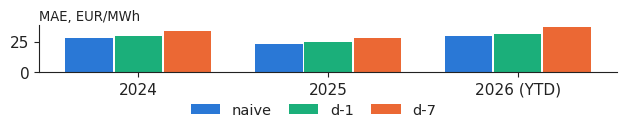

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 1.4))
yrs = [str(y) for y in range(Y - 2, Y + 1)]
for i, (k, lab, col) in enumerate([('naive', 'naive', PAL['RO']), ('lag1', 'd-1', PAL['HU']), ('lag7', 'd-7', PAL['DE_LU'])]):
    ax.bar(np.arange(3) + (i - 1) * 0.26, [nv[y][k] for y in yrs], width=0.25, color=col, label=lab)
ax.set_xticks(range(3))
ax.set_xticklabels([y if y != str(Y) else f'{Y} (YTD)' for y in yrs])
ax.text(0, 1.04, 'MAE, EUR/MWh', transform=ax.transAxes, fontsize=9.5, ha='left', va='bottom')   # unit above the axis
legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.savefig('naive_bar.png', dpi=150, bbox_inches='tight', transparent=True)
plt.show()